In [1]:
# Question: Are late deliveries a regional problem, a seasonal problem, or both?
# Why? The SQL project measured late deliveries by state (query 6) and by month (query 7) separately.
# A heatmap shows both at once and tells us whether the worst months hit every state or only some.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
customers = pd.read_csv('../csv_files/olist_customers_dataset.csv')
order_items = pd.read_csv('../csv_files/olist_order_items_dataset.csv')
orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')
products = pd.read_csv('../csv_files/olist_products_dataset.csv')
payments = pd.read_csv('../csv_files/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../csv_files/olist_order_reviews_dataset.csv')
geolocation = pd.read_csv('../csv_files/olist_geolocation_dataset.csv')
sellers = pd.read_csv('../csv_files/olist_sellers_dataset.csv')
category_translation = pd.read_csv('../csv_files/product_category_name_translation.csv')


# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#category_translation.head()
#customers.tail()
#customers.shape
#customers.describe()
#reviews.info()
#payments.isnull().sum()

print('orders:', orders.shape)
print('customers:', customers.shape)
print('order_items:', order_items.shape)
print('payments:', payments.shape)
print('reviews:', reviews.shape)
print('products:', products.shape)
print('category_translation:', category_translation.shape)

# Data cleanup: Convert all relevant date/time columns to datetime format

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Missing values in the tables that have them

#rint(orders.isnull().sum())
#print(reviews.isnull().sum())
#print(products.isnull().sum())

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
products: (32951, 9)
category_translation: (71, 2)


In [2]:
# Check: reproduce SQL query 6 (all orders with a delivery date, all months)

df_1 = orders.dropna(subset='order_delivered_customer_date') 
df_1 = df_1.merge(customers[['customer_state', 'customer_id']], on='customer_id')

delivered_day = df_1['order_delivered_customer_date'].dt.normalize()
estimated_day = df_1['order_estimated_delivery_date'].dt.normalize()

df_1['is_late'] = (delivered_day - estimated_day).dt.days > 0
total_stats = df_1.groupby('customer_state').agg(
    total_orders=('is_late', 'size'),          
    total_late_orders=('is_late', 'sum')
)
total_stats['overall_late_rate'] = ((total_stats['total_late_orders'] / total_stats['total_orders']) * 100).round(1)

print(total_stats.sort_values(by='overall_late_rate', ascending=False))

                total_orders  total_late_orders  overall_late_rate
customer_state                                                    
AL                       397                 85               21.4
MA                       717                125               17.4
SE                       335                 51               15.2
PI                       476                 66               13.9
CE                      1279                176               13.8
BA                      3256                396               12.2
RR                        41                  5               12.2
RJ                     12353               1495               12.1
PA                       946                106               11.2
ES                      1995                214               10.7
PB                       517                 54               10.4
TO                       274                 27                9.9
MS                       701                 68               

In [3]:
# Keep delivered orders and add the customer state

df = orders[orders['order_status'] == 'delivered'].dropna(subset='order_delivered_customer_date').copy()
df = df.merge(customers[['customer_state', 'customer_id']], on='customer_id')

# Flag late orders (same rule as in the previous notebook:
# late = delivered at least one day after the estimated date)

delivered_day = df['order_delivered_customer_date'].dt.normalize()
estimated_day = df['order_estimated_delivery_date'].dt.normalize()

df['is_late'] = (delivered_day - estimated_day).dt.days > 0

# Year and month in the form 2017-11, keeping only the full months
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df = df[(df['year_month'] > '2017-01') & (df['year_month'] < '2018-08')]

In [4]:
# The 10 states with the most orders 

top_states = df['customer_state'].value_counts().head(10).index.to_list()

df_top = df[df['customer_state'].isin(top_states)]

In [5]:
# Pivot tables: percent of late orders and number of orders per state and month

late_rate = df_top.pivot_table(index='customer_state', columns='year_month', values='is_late', aggfunc='mean') * 100
order_count = df_top.pivot_table(index='customer_state', columns='year_month', values='is_late', aggfunc='size')

# Hide cells with fewer than 30 orders, because their percentages are not reliable
late_rate = late_rate.where(order_count >= 30)

# Sort the states from the one with the most orders to the one with the fewest
late_rate = late_rate.loc[top_states]

worst_state, worst_month = late_rate.stack().idxmax()
print('Worst case:', worst_state, worst_month, round(late_rate.loc[worst_state, worst_month], 1), '% late')

print(total_stats.sort_values(by='overall_late_rate', ascending=False))

Worst case: ES 2018-03 41.4 % late
                total_orders  total_late_orders  overall_late_rate
customer_state                                                    
AL                       397                 85               21.4
MA                       717                125               17.4
SE                       335                 51               15.2
PI                       476                 66               13.9
CE                      1279                176               13.8
BA                      3256                396               12.2
RR                        41                  5               12.2
RJ                     12353               1495               12.1
PA                       946                106               11.2
ES                      1995                214               10.7
PB                       517                 54               10.4
TO                       274                 27                9.9
MS                       70

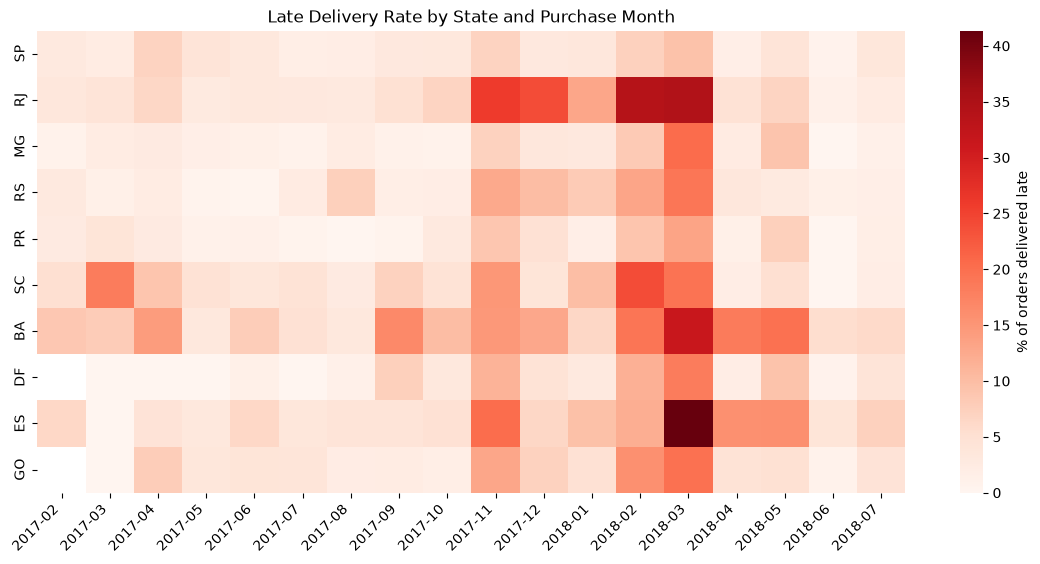

In [6]:
# Heatmap: late delivery rate by state and month

plt.figure(figsize=(14, 6))
sns.heatmap(late_rate, cmap='Reds', cbar_kws={'label': '% of orders delivered late'})
plt.title('Late Delivery Rate by State and Purchase Month')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.savefig('images/late_delivery_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

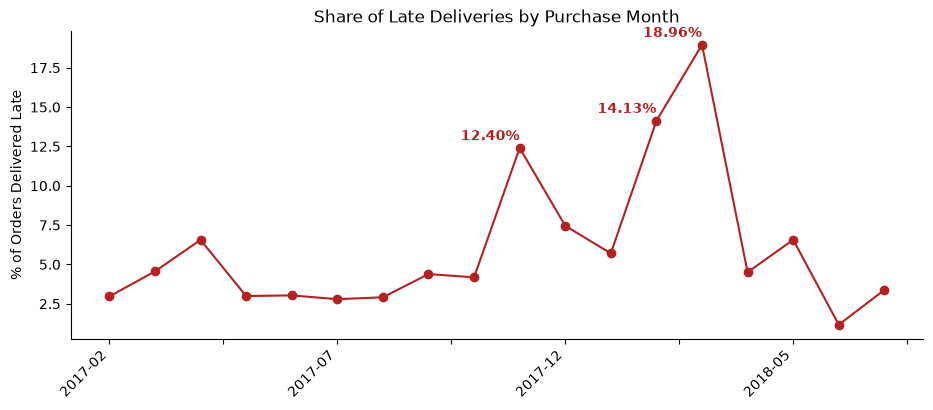

In [7]:
# Line chart: percent of late orders per month, all states together

monthly_late = df.groupby('year_month')['is_late'].mean() * 100
peak_months = monthly_late.nlargest(3).round(2)
#print(peak_months)

monthly_late.plot(kind='line', marker='o', color='firebrick', figsize=(11, 4))

for date, value in peak_months.items():
    x_idx = monthly_late.index.get_loc(date)
    plt.text(
        x_idx, 
        value + 0.5,                  
        f'{value:.2f}%',            
        ha='right',               
        fontweight='bold',
        color='firebrick'
    )

sns.despine()
plt.title('Share of Late Deliveries by Purchase Month')
plt.xlabel('')
plt.ylabel('% of Orders Delivered Late')
plt.xticks(rotation=45, ha='right')
plt.savefig('images/late_delivery_monthly.png', dpi=150, bbox_inches='tight')
plt.show()